# Inferring hidden regimes from filtered probabilities

## Respecting the training boundary in public returns

For an index level \(P_t>0\), the daily log return in percentage points is

$$
r_t=100\left(\log P_t-\log P_{t-1}\right).
$$

Here, \(P_t\) is the public NASDAQ Composite value on date \(t\), \(P_{t-1}\) is the preceding valid value, and \(r_t\) is the continuously compounded daily return measured in percentage points. Removing unavailable levels before taking differences prevents a missing observation from being treated as a zero return.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("13_regime_adaptation");
using CSV, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
include(joinpath("..","support","BookMarkovRegression.jl"))
using .BookMarkovRegression
using RiskLabAI.Backtest: prequential_adaptation
using RiskLabAI.Data: symmetric_cusum_filter,cusum_filter_events_dynamic_threshold
using RiskLabAI.Features: pelt_change_points
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path,DataFrame;missingstring=["","."])
data = sort(dropmissing(raw,:NASDAQCOM),:observation_date)
dates = DateTime.(Date.(data.observation_date))
prices = Float64.(data.NASDAQCOM)
daily_returns = vcat(NaN,100log.(prices[2:end]./prices[1:end-1]))
log_index = 100log.(prices)
violet = "#C084FC"
year_dates = DateTime.(Date(1995):Year(5):Date(2025))
year_ticks = (Dates.value.(year_dates),Dates.format.(year_dates,dateformat"yyyy"))
date_limits = Dates.value.((first(dates)-Day(90),last(dates)+Day(90)))
feature_names = ["Previous return (%)","Previous absolute return (%)","Trailing 5 day mean (%)","Trailing 21 day volatility (%)","Trailing 63 day volatility (%)"]
min_samples,window_size = 756,756

function table(frame,name,caption,label="tab:chapter14-"*replace(name,"_"=>"-"))
    save_table(frame,paths,name;caption,label)
    return nothing
end

function rolling_mean(values,window;minimum_count=window)
    return [index<minimum_count ? NaN : mean(values[max(1,index-window+1):index]) for index in eachindex(values)]
end

function prepare_sequential_data()
    positions = collect(65:length(prices))
    features = hcat(daily_returns[positions.-1],abs.(daily_returns[positions.-1]),[mean(daily_returns[index-5:index-1]) for index in positions],[std(daily_returns[index-21:index-1];corrected=false) for index in positions],[std(daily_returns[index-63:index-1];corrected=false) for index in positions])
    threshold = quantile(abs.(daily_returns[positions[1:min_samples]]),.8)
    targets = Int.(abs.(daily_returns[positions]).>threshold)
    frame = DataFrame(position=positions,date=dates[positions],daily_return=daily_returns[positions],target=targets)
    for (column,name) in enumerate(feature_names)
        frame[!,name] = features[:,column]
    end
    @assert all(isfinite,features)
    @assert allunique(Tuple.(eachrow(features)))
    return frame,features,targets,threshold
end

function run_policy(features,targets;policy=:adaptive,delta=.01,interval=252)
    positions = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(features)))
    models = NamedTuple[]
    scores = fill(NaN,length(targets))
    function fitted(training_x,training_y)
        model = BookLogisticLBFGS.fit_logistic(training_x,training_y;C=1.,class_weight=:balanced,standardize=true,tol=1e-4,max_iter=1000)
        @assert model.converged
        push!(models,(first_position=positions[Tuple(training_x[1,:])],last_position=positions[Tuple(training_x[end,:])],model=model))
        return model
    end
    function predicted(model,row)
        scores[positions[Tuple(row[1,:])]] = only(BookEstimators.decision_function(model,row))
        return BookEstimators.predict(model,row)
    end
    if policy==:adaptive
        result = prequential_adaptation(features,Float64.(targets),nothing;fit_estimator=(_,x,y)->fitted(x,y),predict_estimator=predicted,clone_estimator=identity,loss_function=(actual,prediction)->Float64(actual!=prediction),window_size,min_samples,delta)
        return (;result...,models,scores)
    end
    predictions,losses = fill(NaN,length(targets)),fill(NaN,length(targets))
    refit_indices = [min_samples]
    model = fitted(features[1:min_samples,:],targets[1:min_samples])
    for index in min_samples+1:length(targets)
        predictions[index] = only(predicted(model,features[index:index,:]))
        losses[index] = Float64(predictions[index]!=targets[index])
        if policy==:periodic && (index-min_samples)%interval==0
            model = fitted(features[max(1,index-window_size+1):index,:],targets[max(1,index-window_size+1):index])
            push!(refit_indices,index)
        end
    end
    return (;predictions,losses,refit_indices,alarm_indices=Int[],models,scores)
end

function save_policy(result,name)
    observations = DataFrame(position=1:length(result.predictions),prediction=result.predictions,loss=result.losses,score=result.scores,refit=in.(1:length(result.predictions),Ref(result.refit_indices)),alarm=in.(1:length(result.predictions),Ref(result.alarm_indices)))
    save_data(observations,paths,name*"_observations")
    rows = NamedTuple[]
    for (number,record) in enumerate(result.models)
        model = record.model
        base = (fit=number,first_position=record.first_position,last_position=record.last_position,intercept=model.intercept,objective=model.objective,gradient_norm=model.gradient_norm,converged=model.converged,iterations=model.iterations)
        values = (; (Symbol("coefficient_",i)=>model.coefficients[i] for i in 1:5)...,(Symbol("center_",i)=>model.scaler.center[i] for i in 1:5)...,(Symbol("scale_",i)=>model.scaler.scale[i] for i in 1:5)...)
        push!(rows,merge(base,values))
    end
    save_data(DataFrame(rows),paths,name*"_fits")
    return nothing
end

function event_marks!(figure,event_dates,position,color)
    for date in event_dates
        plot!(figure,fill(Dates.value(date),2),[position-.28,position+.28];color,linewidth=.9,label=false)
    end
    return figure
end


event_marks! (generic function with 1 method)

Row,Field,Value
,String,String
1,Source,Federal Reserve Economic Data
2,Series,"NASDAQ Composite, NASDAQCOM"
3,Observation period,1994-01-03 to 2025-12-31
4,Public URL,https://fred.stlouisfed.org/series/NASDAQCOM
5,Download during execution,No


Row,Quantity,Value
,String,String
1,Valid index levels,8055
2,Daily log returns,8054
3,First valid date,1994-01-03
4,Last valid date,2025-12-31
5,Training cutoff,2014-12-31
6,Post-cutoff return observations,2767


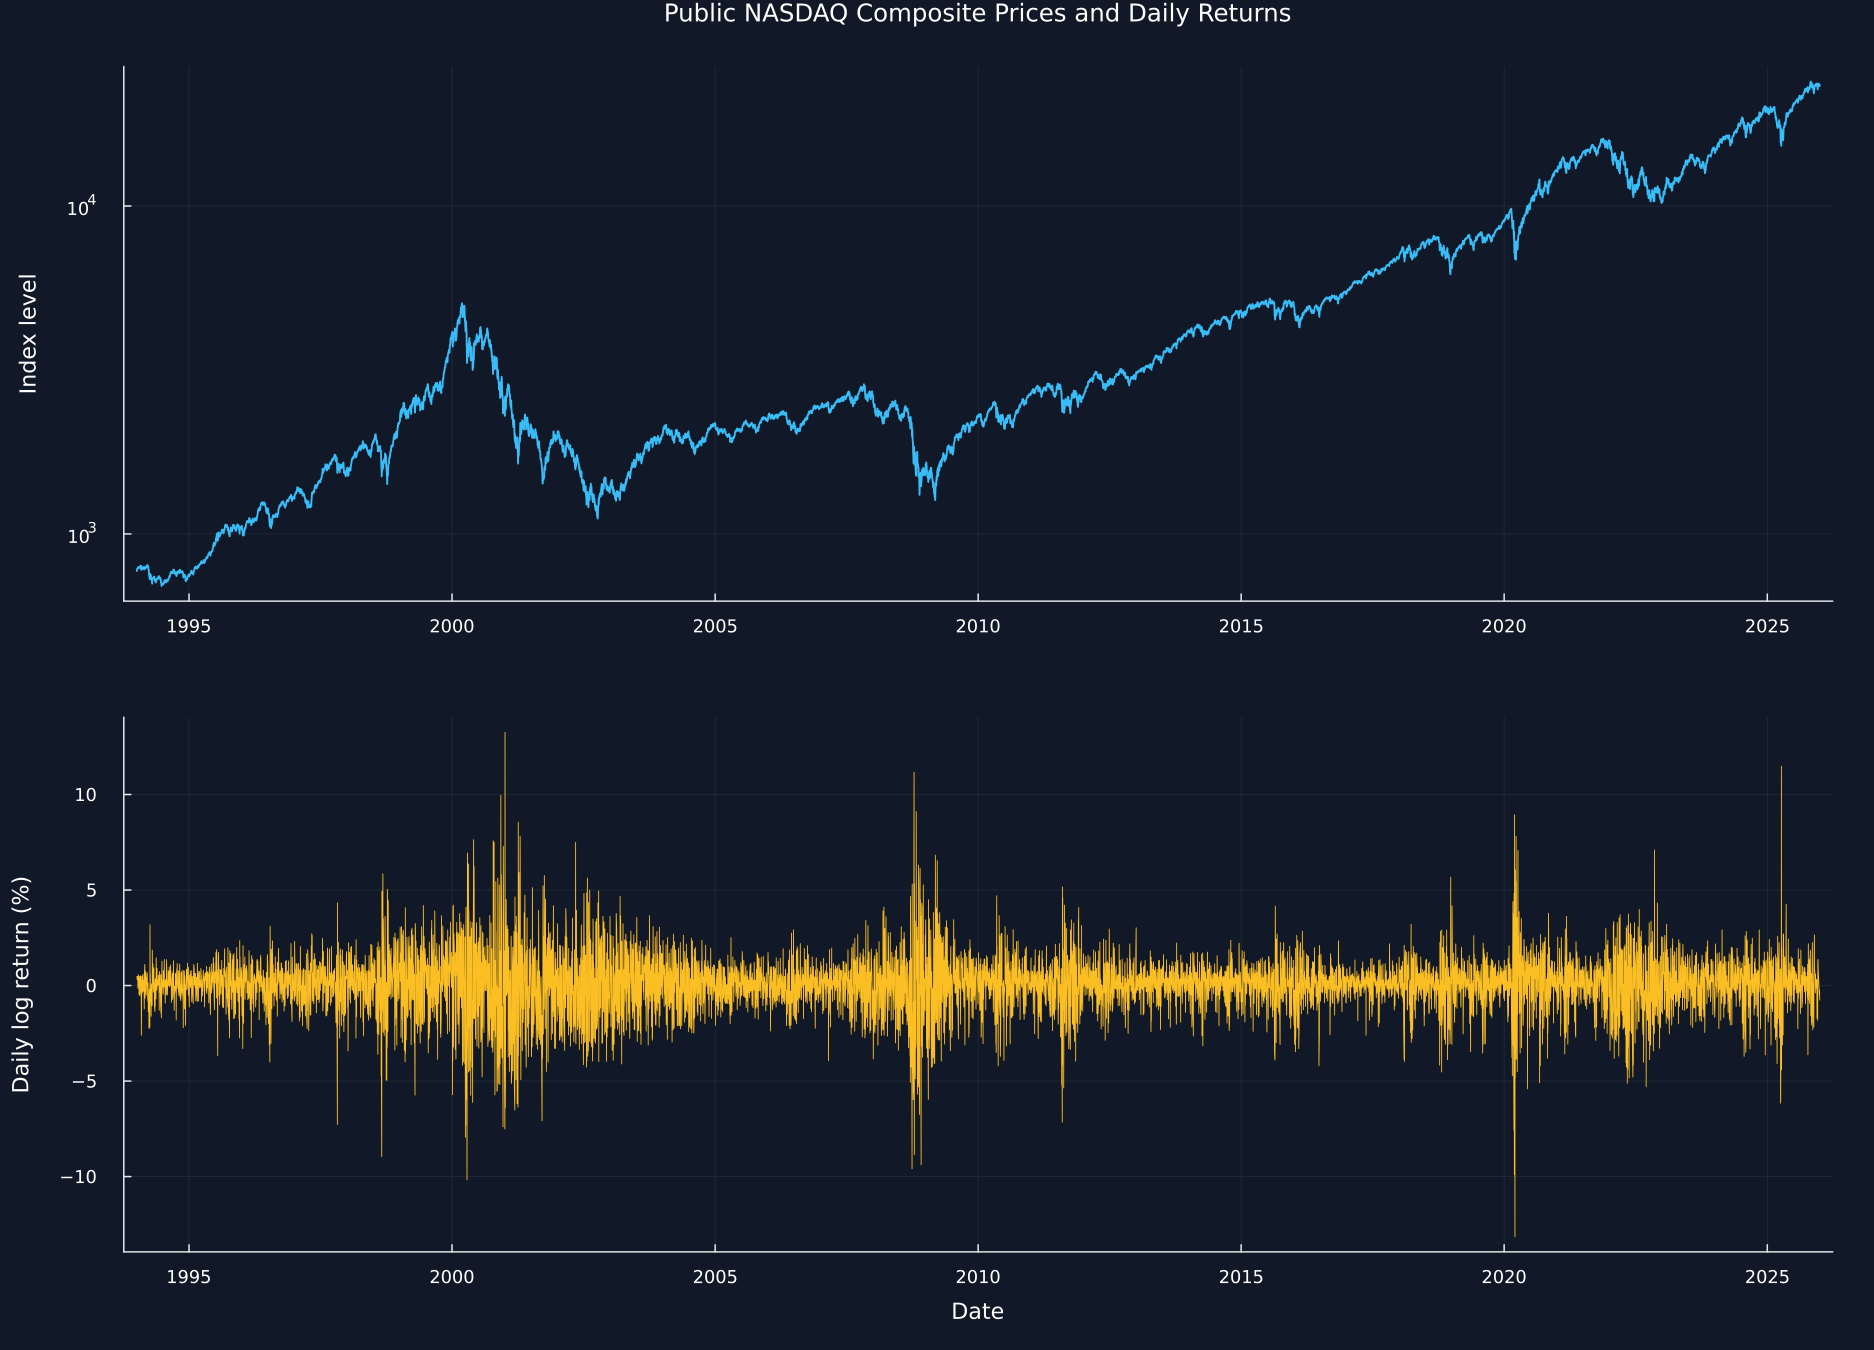

In [2]:
provenance = DataFrame("Field"=>["Source","Series","Observation period","Public URL","Download during execution"],"Value"=>["Federal Reserve Economic Data","NASDAQ Composite, NASDAQCOM",string(Date(first(dates)))*" to "*string(Date(last(dates))),"https://fred.stlouisfed.org/series/NASDAQCOM","No"])
table(provenance,"data_provenance","Public data provenance for the regime and adaptation calculations.")
training_cutoff = DateTime(2014,12,31)
summary = DataFrame("Quantity"=>["Valid index levels","Daily log returns","First valid date","Last valid date","Training cutoff","Post-cutoff return observations"],"Value"=>[string(length(prices)),string(length(prices)-1),string(Date(first(dates))),string(Date(last(dates))),string(Date(training_cutoff)),string(count(>(training_cutoff),dates))])
table(summary,"public_data_summary","Public NASDAQ Composite sample used in Chapter 14.")
history = DataFrame(date=dates,price=prices,daily_return=daily_returns)
save_data(history,paths,"public_price_return_history");
p1 = plot(dates,prices;yscale=:log10,color=palette.cyan,linewidth=1.25,label=false,ylabel="Index level",title="Public NASDAQ Composite Prices and Daily Returns",xticks=year_ticks)
p2 = plot(dates,daily_returns;color=palette.amber,linewidth=.58,label=false,ylabel="Daily log return (%)",xlabel="Date",xticks=year_ticks)
save_figure(plot(p1,p2;layout=(2,1),size=(1250,900),xlims=date_limits),paths,"public_price_return_history")
@assert length(prices)==8055
@assert length(daily_returns)-1==8054


## A Two State Gaussian Return Model

Let the hidden state on date \(t\) be \(S_t\in\{0,1\}\). Conditional on that state, the return is modeled as

$$
r_t=\mu_{S_t}+\sigma_{S_t}\varepsilon_t,
\qquad
\varepsilon_t\sim N(0,1).
$$

Here, \(\mu_j\) is the mean return in state \(j\), \(\sigma_j>0\) is its standard deviation, and \(\varepsilon_t\) is a standard normal innovation. The state follows a Markov chain with

$$
p_{ij}=\Pr(S_t=j\mid S_{t-1}=i),
\qquad
\sum_{j=0}^{1}p_{ij}=1.
$$

The parameter \(p_{ij}\) is the probability of moving from state \(i\) yesterday to state \(j\) today. The transition probabilities are constant in this model. They describe persistence in the fitted statistical states, not permanent economic regimes.

Row,Quantity,Value
,String,String
1,Fitting start,1994-01-04
2,Fitting end,2014-12-31
3,Fitting observations,5287
4,Post-cutoff observations,2767
5,Log likelihood,-8953.767068112855
6,Optimizer converged,true


Row,State label,Original numerical state,Mean return (%),Variance,Standard deviation (%)
,String,Int64,Float64,Float64,Float64
1,Lower volatility state,0,0.0951846,0.833294,0.912849
2,Higher volatility state,1,-0.0721391,5.56022,2.35801


Row,State today,State tomorrow,Probability
,String,String,Float64
1,Lower volatility state,Lower volatility state,0.994956
2,Lower volatility state,Higher volatility state,0.00504442
3,Higher volatility state,Lower volatility state,0.00918733
4,Higher volatility state,Higher volatility state,0.990813


Row,State,Stay probability,Expected duration in trading days
,String,Float64,Float64
1,Lower volatility state,0.994956,198.239
2,Higher volatility state,0.990813,108.846


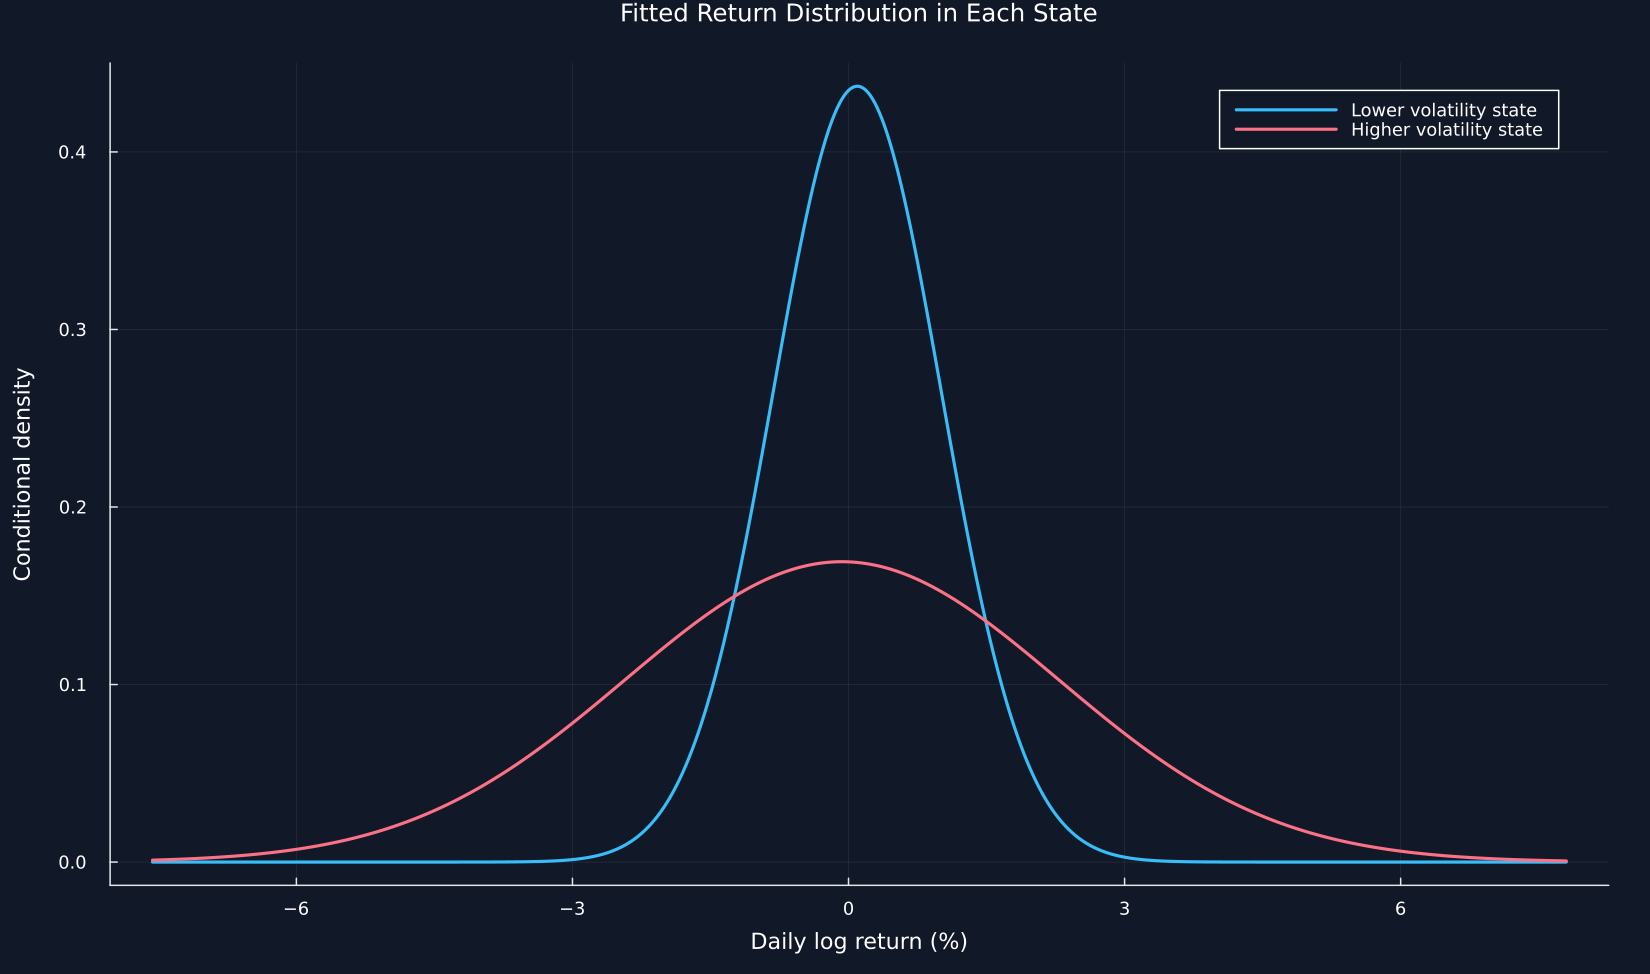

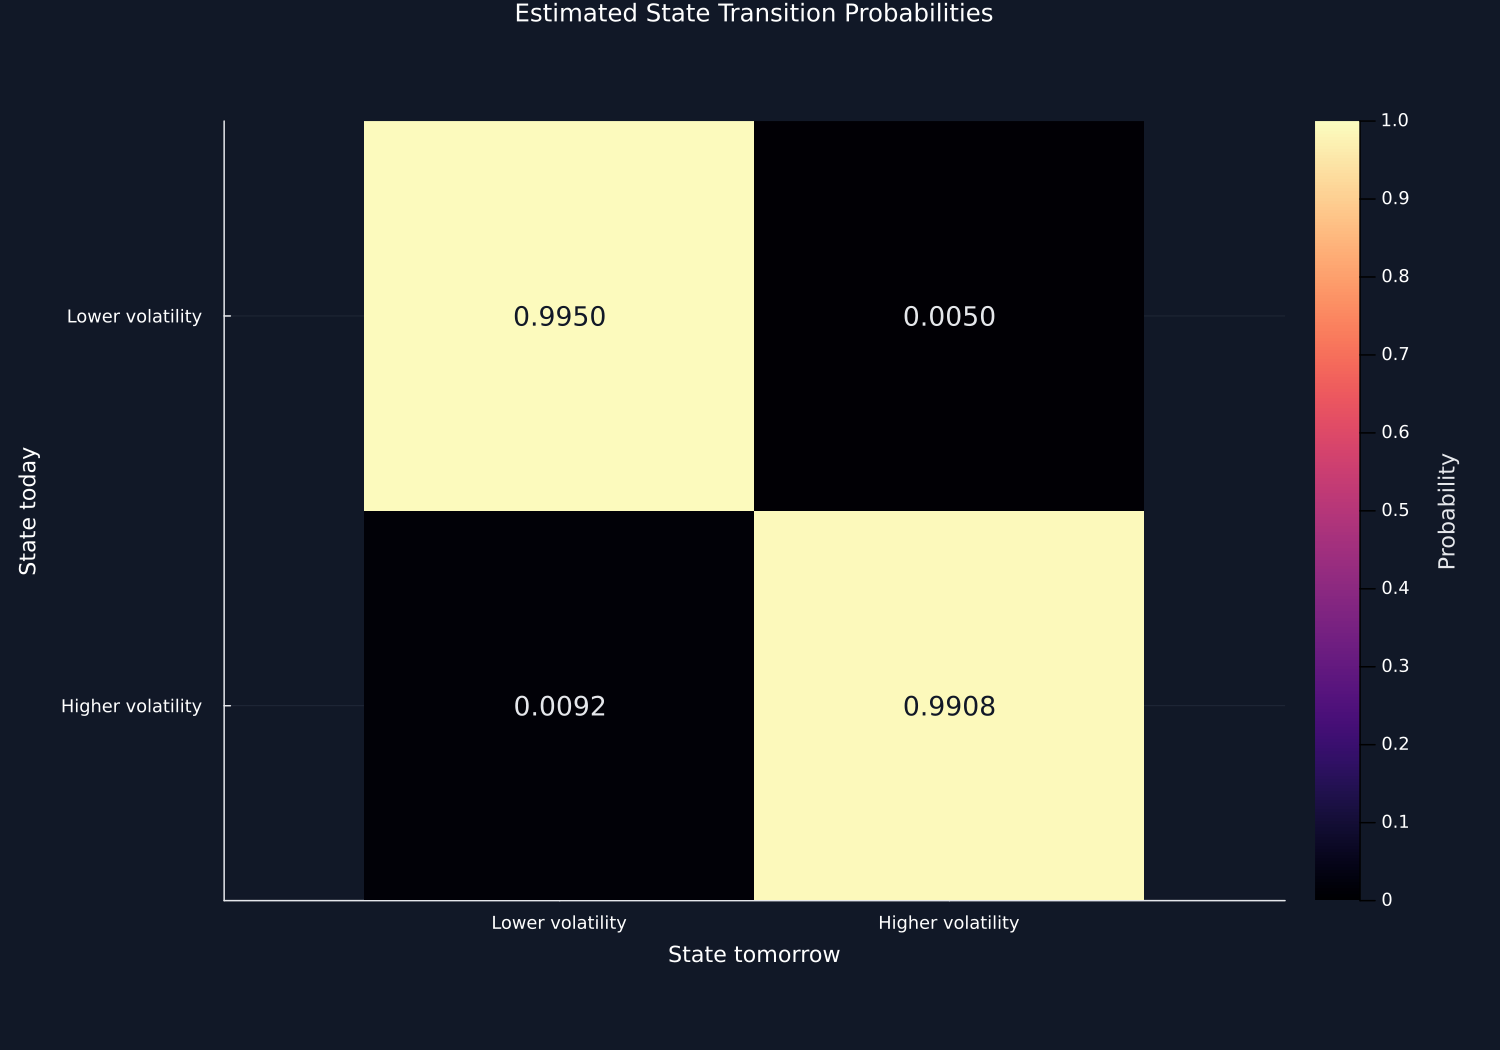

In [3]:
return_dates,returns = dates[2:end],daily_returns[2:end]
training_count = count(<=(training_cutoff),return_dates)
training = returns[1:training_count]
fit_result = fit_markov_regression(training;max_iter=1000)
@assert fit_result.converged
parameters = fit_result.parameters
variances = parameters[5:6]
state_order = sortperm(variances)
low_state,high_state = state_order
state_names = Dict(low_state=>"Lower volatility state",high_state=>"Higher volatility state")
transition = Matrix(transpose(transition_matrix(parameters)))[state_order,state_order]
table(DataFrame("Quantity"=>["Fitting start","Fitting end","Fitting observations","Post-cutoff observations","Log likelihood","Optimizer converged"],"Value"=>[string(Date(first(return_dates))),string(Date(return_dates[training_count])),string(training_count),string(length(returns)-training_count),string(fit_result.loglikelihood),string(fit_result.converged)]),"state_model_sample","Fitting sample and numerical status of the two state model.")
state_parameters = DataFrame("State label"=>[state_names[state] for state in state_order],"Original numerical state"=>state_order.-1,"Mean return (%)"=>parameters[state_order.+2],"Variance"=>variances[state_order],"Standard deviation (%)"=>sqrt.(variances[state_order]))
table(state_parameters,"state_parameters","Fitted Gaussian parameters ordered by return variance.")
transition_table = DataFrame("State today"=>[state_names[state_order[i]] for i in 1:2 for j in 1:2],"State tomorrow"=>[state_names[state_order[j]] for i in 1:2 for j in 1:2],"Probability"=>[transition[i,j] for i in 1:2 for j in 1:2])
table(transition_table,"transition_probabilities","Estimated transition probabilities between the two fitted states.")
table(DataFrame("State"=>[state_names[state] for state in state_order],"Stay probability"=>diag(transition),"Expected duration in trading days"=>1 ./ (1 .- diag(transition))),"expected_state_durations","Expected state durations implied by constant transition probabilities.")
save_data(DataFrame(parameter=["p00","p01","mean0","mean1","variance0","variance1"],value=parameters,em_start=fit_result.em_start),paths,"markov_parameters");
save_data(DataFrame(loglikelihood=[fit_result.loglikelihood],gradient_norm=[fit_result.gradient_norm],iterations=[fit_result.iterations],training_count=[training_count]),paths,"markov_optimizer");
density_grid = collect(range(quantile(returns,.001),quantile(returns,.999);length=600))
density_rows = DataFrame(return_value=Float64[],density=Float64[],state=String[])
p1 = plot(;xlabel="Daily log return (%)",ylabel="Conditional density",title="Fitted Return Distribution in Each State",legend=:topright,size=(1100,650))
for (state,color) in [(low_state,palette.cyan),(high_state,palette.rose)]
    density = exp.(-0.5 .* (density_grid.-parameters[state+2]).^2 ./ variances[state])./sqrt(2pi*variances[state])
    plot!(p1,density_grid,density;color,linewidth=2.1,label=state_names[state])
    append!(density_rows,DataFrame(return_value=density_grid,density=density,state=fill(state_names[state],600)))
end
save_data(density_rows,paths,"state_density_curves");
save_figure(p1,paths,"state_density_distributions")
save_data(transition_table,paths,"transition_matrix");
p2 = heatmap(1:2,1:2,transition;c=:magma,clims=(0,1),yflip=true,aspect_ratio=:equal,xticks=(1:2,["Lower volatility","Higher volatility"]),yticks=(1:2,["Lower volatility","Higher volatility"]),xlabel="State tomorrow",ylabel="State today",title="Estimated State Transition Probabilities",colorbar_title="Probability",size=(1000,700))
for i in 1:2,j in 1:2
    annotate!(p2,j,i,text(@sprintf("%.4f",transition[i,j]),12,transition[i,j]<.6 ? palette.text : palette.background))
end
save_figure(p2,paths,"transition_matrix")
@assert training_count==5287
@assert all(parameters[5:6].>0)


## Filtering with Frozen Parameters

Suppose \(\pi_{t-1\mid t-1,i}\) is the filtered probability of state \(i\) after observing returns through date \(t-1\). The one-step state prediction is

$$
\pi_{t\mid t-1,j}
=\sum_{i=0}^{1}p_{ij}\pi_{t-1\mid t-1,i}.
$$

Here, \(\pi_{t\mid t-1,j}\) is the probability of state \(j\) before observing \(r_t\), and \(p_{ij}\) is the transition probability from state \(i\) to state \(j\). After \(r_t\) is observed, the filtered probability becomes

$$
\pi_{t\mid t,j}
=\frac{f_j(r_t)\pi_{t\mid t-1,j}}
{\sum_{\ell=0}^{1}f_\ell(r_t)\pi_{t\mid t-1,\ell}}.
$$

The function \(f_j(r_t)\) is the Gaussian density of the observed return under state \(j\). The denominator normalizes the two state probabilities so that they sum to one. The parameters are fitted only through December 2014 and are then held fixed. Filtering after that date uses each new return but does not re-estimate the means, variances, or transition probabilities.

Row,Check,Maximum absolute error,Tolerance,Result
,String,Float64,Float64,Bool
1,Filtered probabilities sum to one,2.22045e-16,1.0e-12,true
2,Transition rows sum to one,0.0,1.0e-12,true
3,Fitted variances are positive,0.0,0.0,true
4,Later returns do not alter earlier filtered probabilities,0.0,1.0e-12,true
5,Exchanging state labels only reverses probability columns,1.83187e-15,1.0e-12,true


Row,date,daily_return,filtered_high
,DateTime,Float64,Float64
1,1998-08-31T00:00:00,-8.95361,1.0
2,2000-04-03T00:00:00,-7.94255,1.0
3,2000-04-14T00:00:00,-10.1684,1.0
4,2000-12-05T00:00:00,9.96364,1.0
5,2001-01-03T00:00:00,13.2546,1.0
6,2001-04-05T00:00:00,8.54541,1.0
7,2008-09-29T00:00:00,-9.58769,1.0
8,2008-10-13T00:00:00,11.1594,1.0
9,2008-10-15T00:00:00,-8.85021,1.0


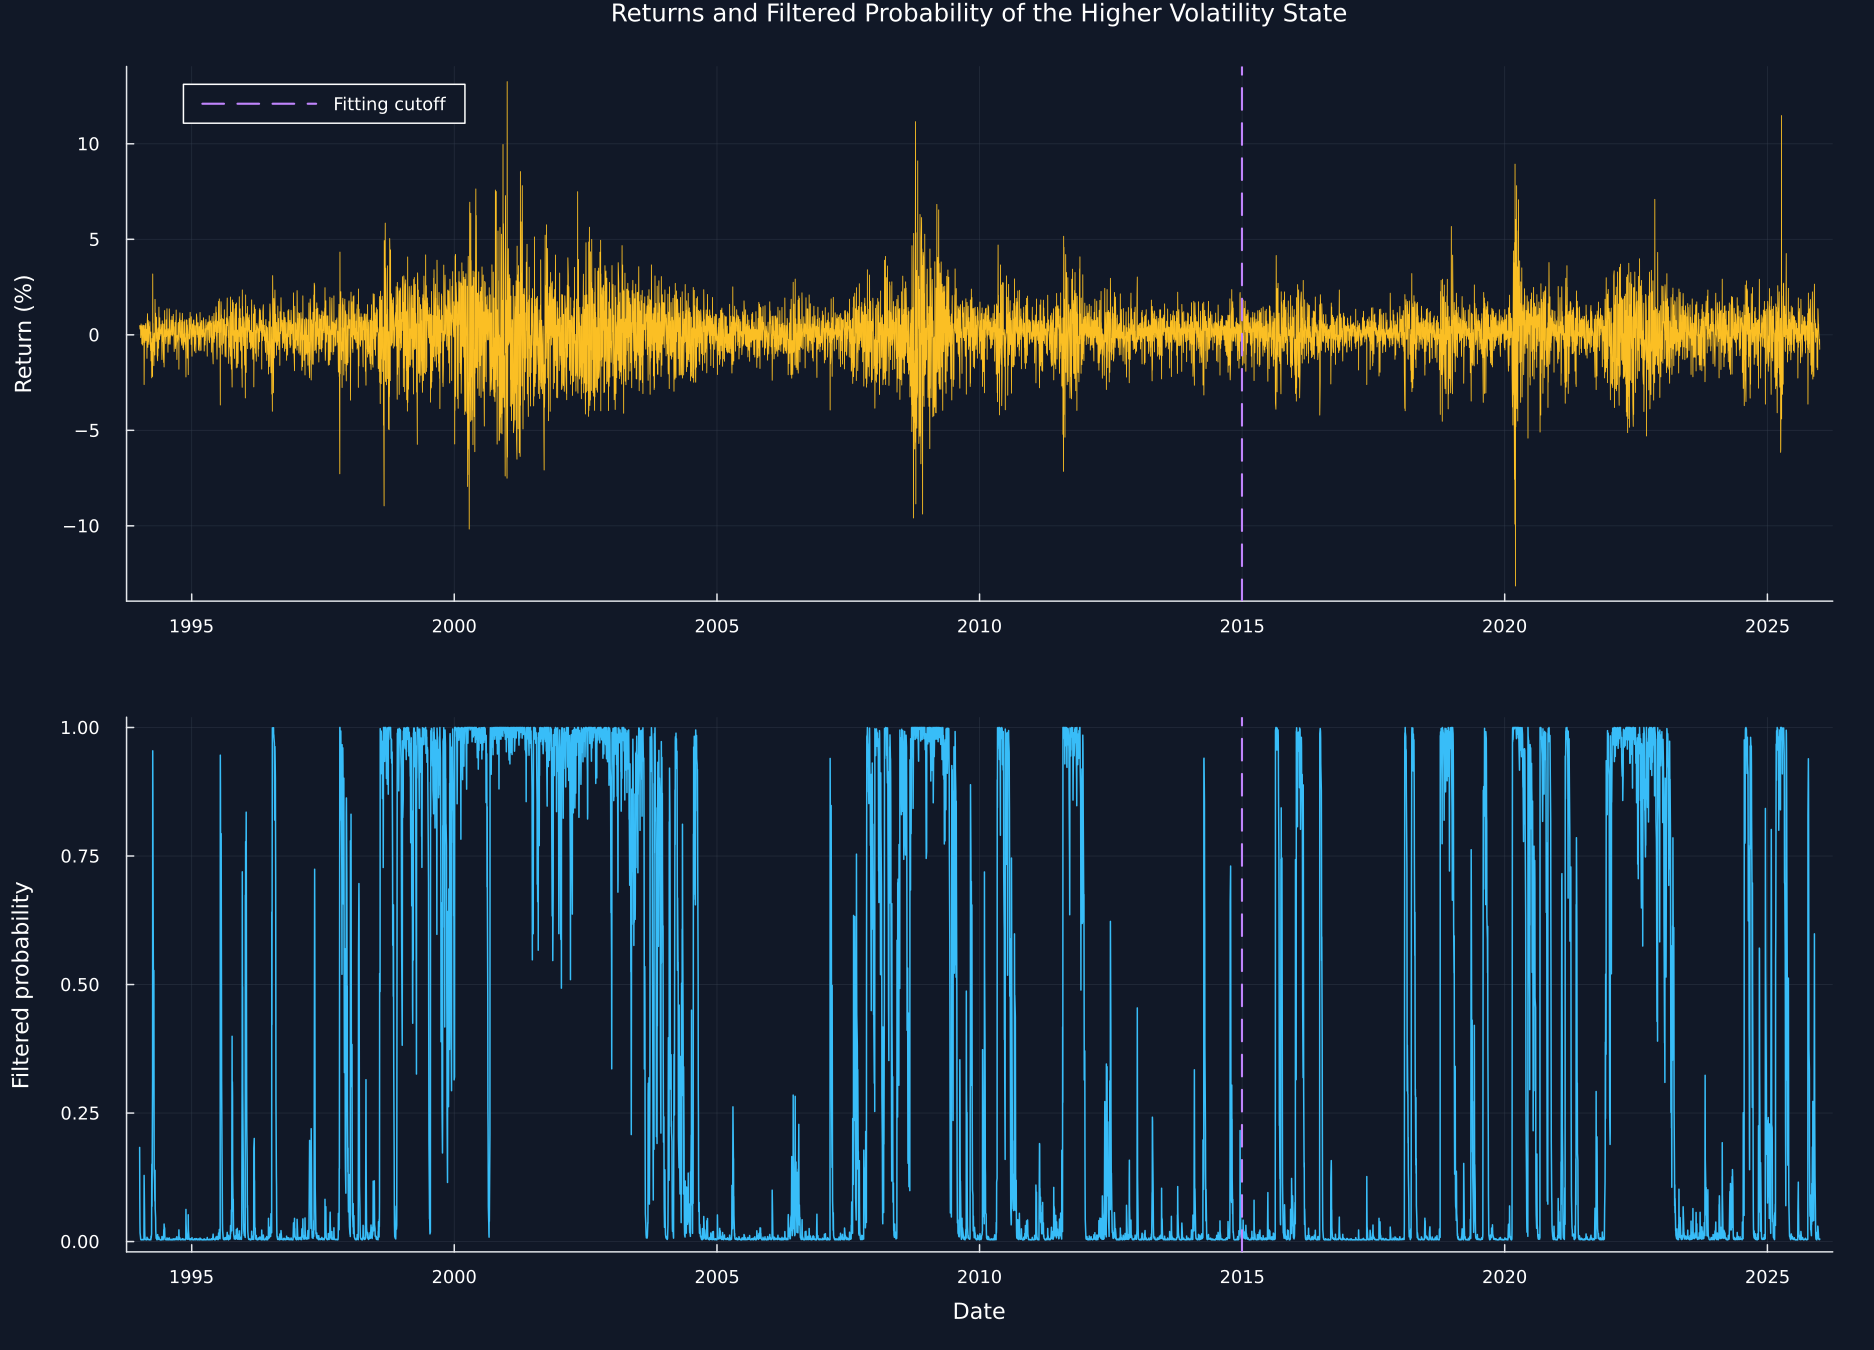

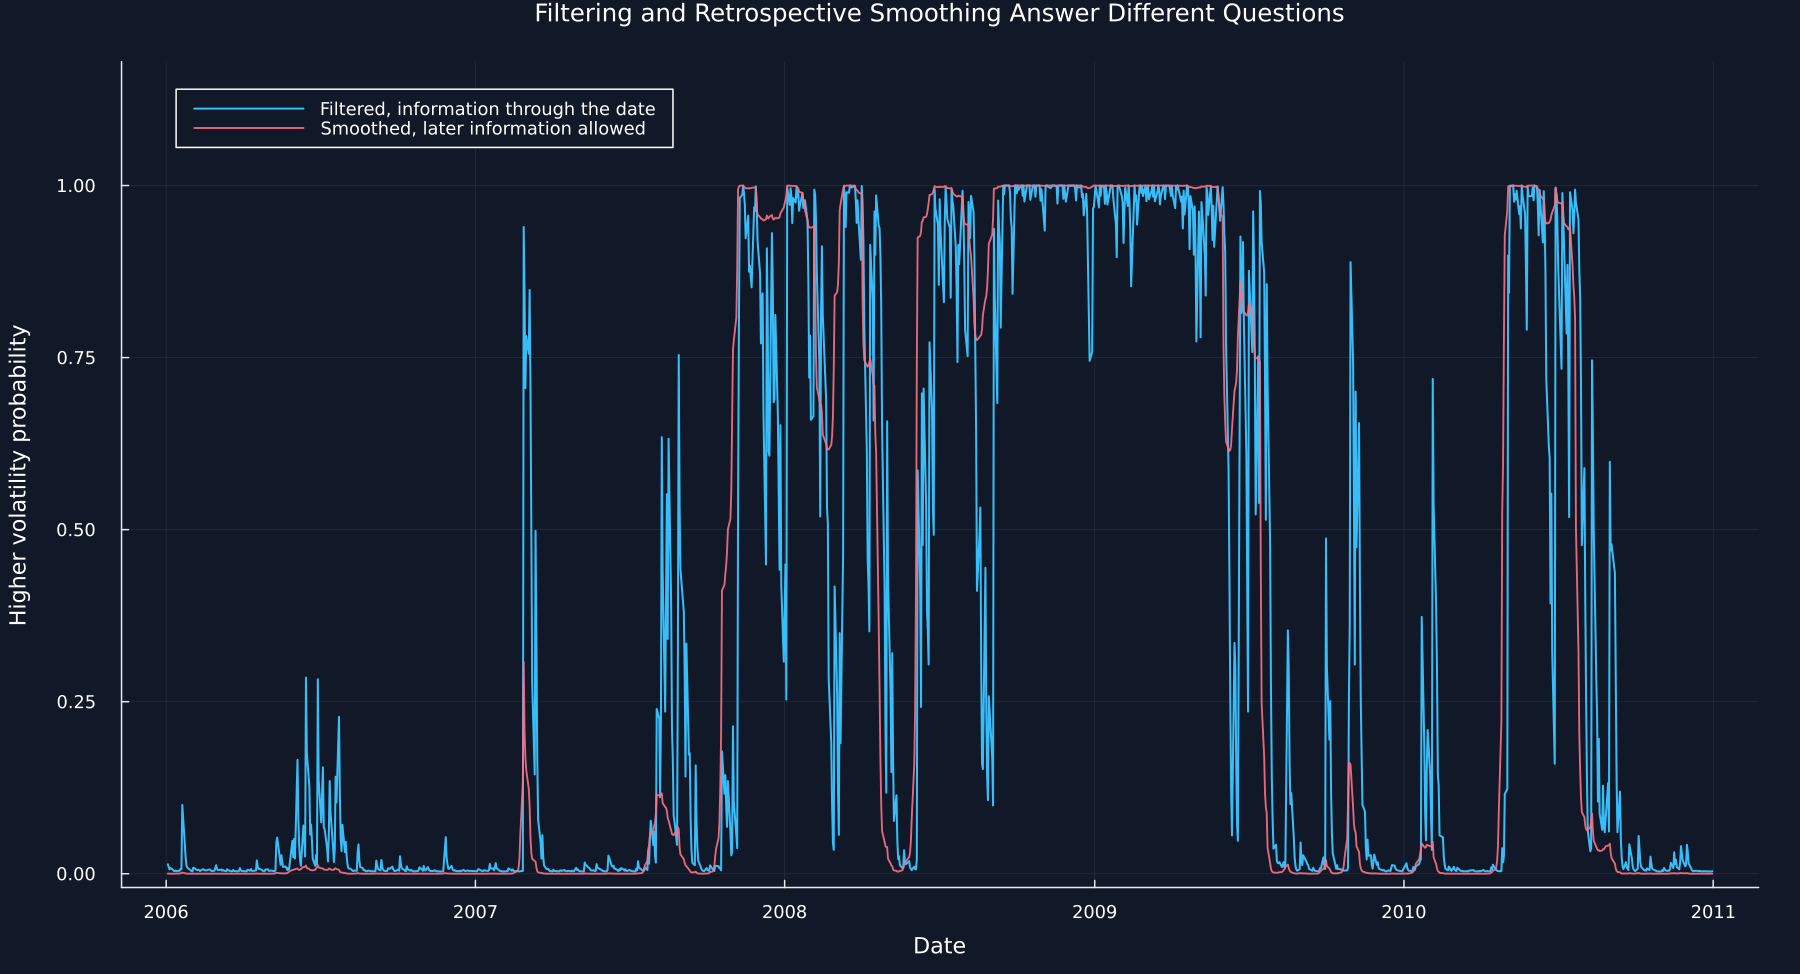

In [4]:
full_result = smooth_markov(returns,parameters)
filtered_raw,smoothed_raw = full_result.filtered,full_result.smoothed
probabilities = DataFrame(date=return_dates,daily_return=returns,filtered_low=filtered_raw[:,low_state],filtered_high=filtered_raw[:,high_state],smoothed_high=smoothed_raw[:,high_state],training_period=return_dates.<=training_cutoff)
save_data(probabilities,paths,"state_probabilities");
save_data(DataFrame(position=1:length(returns),predicted_0=full_result.predicted[:,1],predicted_1=full_result.predicted[:,2],filtered_0=filtered_raw[:,1],filtered_1=filtered_raw[:,2],smoothed_0=smoothed_raw[:,1],smoothed_1=smoothed_raw[:,2],loglikelihood=full_result.contributions),paths,"markov_filter_evidence");
prefix_filtered = filter_markov(training,parameters).filtered
swapped_parameters = [1-parameters[2],1-parameters[1],parameters[4],parameters[3],parameters[6],parameters[5]]
swapped_filtered = filter_markov(returns,swapped_parameters).filtered
check_errors = [maximum(abs.(sum(filtered_raw;dims=2).-1)),maximum(abs.(sum(transition;dims=2).-1)),max(0.,-minimum(variances)),maximum(abs.(filtered_raw[1:training_count,:].-prefix_filtered)),maximum(abs.(filtered_raw.-swapped_filtered[:,[2,1]]))]
check_results = [check_errors[1]<1e-12,check_errors[2]<1e-12,all(variances.>0),check_errors[4]<1e-12,check_errors[5]<1e-12]
table(DataFrame("Check"=>["Filtered probabilities sum to one","Transition rows sum to one","Fitted variances are positive","Later returns do not alter earlier filtered probabilities","Exchanging state labels only reverses probability columns"],"Maximum absolute error"=>check_errors,"Tolerance"=>[1e-12,1e-12,0.,1e-12,1e-12],"Result"=>check_results),"markov_checks","Numerical checks for the fitted state model and its filtered probabilities.")
@assert all(check_results)
extremes = sort(probabilities[sortperm(probabilities.filtered_high;rev=true)[1:10],[:date,:daily_return,:filtered_high]],:date)
table(extremes,"high_state_probability_dates","Dates with the ten largest filtered probabilities of the higher volatility state.")
p1 = plot(return_dates,returns;color=palette.amber,linewidth=.58,label=false,ylabel="Return (%)",title="Returns and Filtered Probability of the Higher Volatility State",xticks=year_ticks,legend=:topleft)
vline!(p1,[Dates.value(training_cutoff)];color=violet,linestyle=:dash,linewidth=1.4,label="Fitting cutoff")
p2 = plot(return_dates,probabilities.filtered_high;color=palette.cyan,linewidth=1,label=false,ylabel="Filtered probability",xlabel="Date",ylims=(-.02,1.02),xticks=year_ticks)
vline!(p2,[Dates.value(training_cutoff)];color=violet,linestyle=:dash,linewidth=1.4,label=false)
save_figure(plot(p1,p2;layout=(2,1),size=(1250,900),xlims=date_limits),paths,"filtered_state_probability")
contrast = probabilities[DateTime(2006).<=return_dates.<=DateTime(2010,12,31),[:date,:filtered_high,:smoothed_high]]
save_data(contrast,paths,"filtered_smoothed_contrast");
contrast_ticks = DateTime.(Date(2006):Year(1):Date(2011))
p3 = plot(contrast.date,contrast.filtered_high;color=palette.cyan,linewidth=1.35,label="Filtered, information through the date",xlabel="Date",ylabel="Higher volatility probability",ylims=(-.02,1.18),title="Filtering and Retrospective Smoothing Answer Different Questions",legend=:topleft,xticks=(Dates.value.(contrast_ticks),Dates.format.(contrast_ticks,dateformat"yyyy")),size=(1200,650))
plot!(p3,contrast.date,contrast.smoothed_high;color=palette.rose,linewidth=1.25,alpha=.9,label="Smoothed, later information allowed")
save_figure(p3,paths,"filtered_smoothed_contrast")


## Interpreting learned state labels

The numerical names zero and one have no economic meaning. This notebook calls the fitted state with the smaller conditional variance the lower volatility state and the other state the higher volatility state. A filtered probability uses returns available through the date being assessed. A smoothed probability can use later returns and is included only as a retrospective contrast.

The fitted states summarize two Gaussian components under constant transition probabilities. They do not prove that the market has exactly two economic regimes, identify a structural cause, or supply a trading rule. A high filtered probability means that the observed returns are more consistent with the fitted higher variance component under this model.

In [5]:
table(DataFrame("Item" => ["State label", "Filtered probability", "Smoothed probability", "Transition probability", "Public example"],"Permitted reading" => ["Ordered by fitted return variance", "Probability under the fitted model using information through the date", "Retrospective comparison using later observations", "Persistence under the constant transition model", "Description of one index and period"],"Excluded reading" => ["A named economic regime", "A directly observed market state", "An input to a live decision", "A permanent law of market behavior", "Evidence of forecasting or investment superiority"]),"state_interpretation_limits","Interpretation boundaries for the two state public illustration.","tab:chapter14-state-interpretation-limits")
@assert all(isfinite,parameters)
@assert all(0 .<= filtered_raw .<= 1)
@assert all(0 .<= smoothed_raw .<= 1)
@assert maximum(abs.(sum(smoothed_raw;dims=2).-1))<1e-12
@assert length(returns)==8054
@assert nrow(contrast)>0
@assert nrow(extremes)==10


Row,Item,Permitted reading,Excluded reading
,String,String,String
1,State label,Ordered by fitted return variance,A named economic regime
2,Filtered probability,Probability under the fitted model using information through the date,A directly observed market state
3,Smoothed probability,Retrospective comparison using later observations,An input to a live decision
4,Transition probability,Persistence under the constant transition model,A permanent law of market behavior
5,Public example,Description of one index and period,Evidence of forecasting or investment superiority
